<h1 align='center'> Price prediction <h1/>

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [71]:
df=pd.read_csv('data/survey_results.csv')

print(df.shape)
df.head()

(30010, 17)


,respondent_id,age,gender,zone,occupation,income_levels,consume_frequency(weekly),current_brand,preferable_consumption_size,awareness_of_other_brands,reasons_for_choosing_brands,flavor_preference,purchase_channel,packaging_preference,health_concerns,typical_consumption_situations,price_range
0,R00001,30,M,Urban,Working Professional,<10L,3-4 times,Newcomer,Medium (500 ml),0 to 1,Price,Traditional,Online,Simple,Medium (Moderately health-conscious),"Active (eg. Sports, gym)",100-150
1,R00002,46,F,Metro,Working Professional,> 35L,5-7 times,Established,Medium (500 ml),2 to 4,Quality,Exotic,Retail Store,Premium,Medium (Moderately health-conscious),Social (eg. Parties),200-250
2,R00003,41,F,Rural,Working Professional,> 35L,3-4 times,Newcomer,Medium (500 ml),2 to 4,Availability,Traditional,Retail Store,Premium,Medium (Moderately health-conscious),"Active (eg. Sports, gym)",200-250
3,R00004,33,F,Urban,Working Professional,16L - 25L,5-7 times,Newcomer,Medium (500 ml),0 to 1,Brand Reputation,Exotic,Online,Eco-Friendly,Low (Not very concerned),"Active (eg. Sports, gym)",150-200
4,R00005,23,M,Metro,Student,NaN,3-4 times,Established,Medium (500 ml),0 to 1,Availability,Traditional,Online,Premium,Medium (Moderately health-conscious),"Active (eg. Sports, gym)",50-100


In [72]:
df.columns

Index(['respondent_id', 'age', 'gender', 'zone', 'occupation', 'income_levels',
       'consume_frequency(weekly)', 'current_brand',
       'preferable_consumption_size', 'awareness_of_other_brands',
       'reasons_for_choosing_brands', 'flavor_preference', 'purchase_channel',
       'packaging_preference', 'health_concerns',
       'typical_consumption_situations', 'price_range'],
      dtype='str')

In [73]:
df.duplicated().sum()

10

In [74]:
df[df.duplicated(keep=False)]

,respondent_id,age,gender,zone,occupation,income_levels,consume_frequency(weekly),current_brand,preferable_consumption_size,awareness_of_other_brands,reasons_for_choosing_brands,flavor_preference,purchase_channel,packaging_preference,health_concerns,typical_consumption_situations,price_range
2308,R02309,27,M,Urban,Working Professional,16L - 25L,3-4 times,Newcomer,Small (250 ml),2 to 4,Brand Reputation,Traditional,Online,Simple,Medium (Moderately health-conscious),Social (eg. Parties),150-200
2309,R02309,27,M,Urban,Working Professional,16L - 25L,3-4 times,Newcomer,Small (250 ml),2 to 4,Brand Reputation,Traditional,Online,Simple,Medium (Moderately health-conscious),Social (eg. Parties),150-200
2665,R02665,61,M,Metro,Entrepreneur,16L - 25L,3-4 times,Established,Medium (500 ml),above 4,Brand Reputation,Exotic,Retail Store,Simple,High (Very health-conscious),"Active (eg. Sports, gym)",200-250
2666,R02665,61,M,Metro,Entrepreneur,16L - 25L,3-4 times,Established,Medium (500 ml),above 4,Brand Reputation,Exotic,Retail Store,Simple,High (Very health-conscious),"Active (eg. Sports, gym)",200-250
5150,R05149,21,M,Semi-Urban,Student,NaN,3-4 times,Established,Small (250 ml),2 to 4,Availability,Traditional,Retail Store,Simple,Low (Not very concerned),"Active (eg. Sports, gym)",50-100
5151,R05149,21,M,Semi-Urban,Student,NaN,3-4 times,Established,Small (250 ml),2 to 4,Availability,Traditional,Retail Store,Simple,Low (Not very concerned),"Active (eg. Sports, gym)",50-100
7793,R07791,25,M,Metro,Working Professional,<10L,3-4 times,Newcomer,Medium (500 ml),2 to 4,Availability,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150
7794,R07791,25,M,Metro,Working Professional,<10L,3-4 times,Newcomer,Medium (500 ml),2 to 4,Availability,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150
8515,R08512,20,F,Metro,Student,NaN,5-7 times,Established,Large (1 L),0 to 1,Price,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150
8516,R08512,20,F,Metro,Student,NaN,5-7 times,Established,Large (1 L),0 to 1,Price,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150


These are the Occurances of the duplicates in the dataset, Lets keep one occurance and remove the duplicate occurances

In [75]:
df = df.drop_duplicates()

In [76]:
df.info()

<class 'pandas.DataFrame'>
Index: 30000 entries, 0 to 30009
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   respondent_id                   30000 non-null  str  
 1   age                             30000 non-null  int64
 2   gender                          30000 non-null  str  
 3   zone                            30000 non-null  str  
 4   occupation                      30000 non-null  str  
 5   income_levels                   21939 non-null  str  
 6   consume_frequency(weekly)       29992 non-null  str  
 7   current_brand                   30000 non-null  str  
 8   preferable_consumption_size     30000 non-null  str  
 9   awareness_of_other_brands       30000 non-null  str  
 10  reasons_for_choosing_brands     30000 non-null  str  
 11  flavor_preference               30000 non-null  str  
 12  purchase_channel                29990 non-null  str  
 13  packaging_prefere

In [77]:
df.describe()

,age
count,30000.000000
mean,33.048167
std,13.438904
min,18.000000
25%,23.000000
50%,31.000000
75%,40.000000
max,604.000000


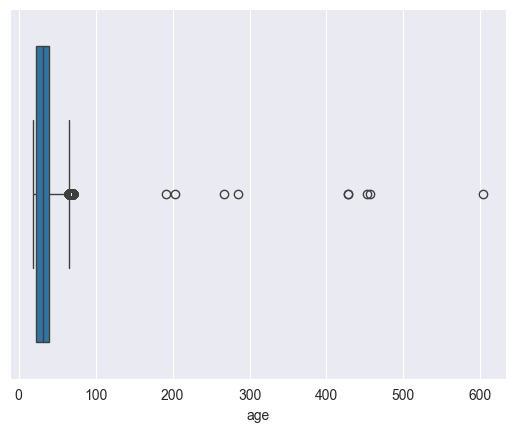

In [78]:
sns.boxplot(x=df['age'])
plt.show()

we found that the age column with many outliers

In [79]:
print(df['age'].value_counts().sort_index())

age
18     1320
19     1352
20     1261
21     1294
22     1327
       ... 
285       1
428       2
453       1
457       1
604       1
Name: count, Length: 61, dtype: int64


In [80]:
(df['age'] <1).sum()

0

In [81]:
df[df['age'] > 100]

,respondent_id,age,gender,zone,occupation,income_levels,consume_frequency(weekly),current_brand,preferable_consumption_size,awareness_of_other_brands,reasons_for_choosing_brands,flavor_preference,purchase_channel,packaging_preference,health_concerns,typical_consumption_situations,price_range
3099,R03098,453,M,Metro,Working Professional,26L - 35L,3-4 times,Established,Medium (500 ml),2 to 4,Brand Reputation,Traditional,Retail Store,Premium,Medium (Moderately health-conscious),Social (eg. Parties),200-250
6262,R06260,428,M,Urban,Entrepreneur,16L - 25L,5-7 times,Established,Large (1 L),above 4,Quality,Exotic,Online,Simple,High (Very health-conscious),Social (eg. Parties),200-250
12403,R12398,604,M,Metro,Retired,<10L,0-2 times,Newcomer,Small (250 ml),2 to 4,Availability,Traditional,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),100-150
22549,R22542,457,M,Metro,Working Professional,16L - 25L,3-4 times,Newcomer,Small (250 ml),2 to 4,Price,Traditional,Online,Premium,High (Very health-conscious),Casual (eg. At home),200-250
22918,R22911,267,F,Metro,Working Professional,16L - 25L,3-4 times,Established,Medium (500 ml),above 4,Brand Reputation,Exotic,Online,Eco-Friendly,Low (Not very concerned),"Active (eg. Sports, gym)",150-200
24958,R24950,285,M,Semi-Urban,Working Professional,> 35L,0-2 times,Newcomer,Small (250 ml),2 to 4,Price,Traditional,Online,Simple,Medium (Moderately health-conscious),"Active (eg. Sports, gym)",150-200
24960,R24952,192,F,Urban,Student,NaN,3-4 times,Newcomer,Medium (500 ml),0 to 1,Price,Traditional,Online,Simple,Low (Not very concerned),"Active (eg. Sports, gym)",50-100
25105,R25096,203,M,Metro,Working Professional,16L - 25L,0-2 times,Established,Small (250 ml),2 to 4,Brand Reputation,Exotic,Retail Store,Premium,High (Very health-conscious),"Active (eg. Sports, gym)",150-200
28770,R28761,428,F,Rural,Working Professional,26L - 35L,0-2 times,Established,Small (250 ml),2 to 4,Brand Reputation,Exotic,Online,Simple,Medium (Moderately health-conscious),Casual (eg. At home),150-200


In [82]:
df = df[df['age'] <= 100]

In [83]:
(df['age'] > 100).sum()

0

In [84]:
df.isnull().sum()

respondent_id                        0
age                                  0
gender                               0
zone                                 0
occupation                           0
income_levels                     8060
consume_frequency(weekly)            8
current_brand                        0
preferable_consumption_size          0
awareness_of_other_brands            0
reasons_for_choosing_brands          0
flavor_preference                    0
purchase_channel                    10
packaging_preference                 0
health_concerns                      0
typical_consumption_situations       0
price_range                          0
dtype: int64

income_levels, purchase_channel, consume_frequency(weekly) have the Missing Values

### income_levels column

In [85]:
df.income_levels.value_counts()

income_levels
16L - 25L    5897
10L - 15L    5251
<10L         4661
26L - 35L    3872
> 35L        2250
Name: count, dtype: int64

In [86]:
df.income_levels = df.income_levels.fillna('Not Reported')

### purchase_channel column

In [87]:
df['purchase_channel'].isnull().sum()

10

In [88]:
df['purchase_channel'] = df['purchase_channel'].fillna(df['purchase_channel'].mode().iloc[0])

In [89]:
df['purchase_channel'].isnull().sum()

0

### consume_frequency(weekly) column

In [90]:
df['consume_frequency(weekly)'].mode().iloc[0]

'3-4 times'

In [91]:
df['consume_frequency(weekly)'] = df['consume_frequency(weekly)'].fillna(df['consume_frequency(weekly)'].mode().iloc[0])

In [92]:
df['consume_frequency(weekly)'].isnull().sum()


0

In [93]:
df.columns

Index(['respondent_id', 'age', 'gender', 'zone', 'occupation', 'income_levels',
       'consume_frequency(weekly)', 'current_brand',
       'preferable_consumption_size', 'awareness_of_other_brands',
       'reasons_for_choosing_brands', 'flavor_preference', 'purchase_channel',
       'packaging_preference', 'health_concerns',
       'typical_consumption_situations', 'price_range'],
      dtype='str')

In [94]:
df.zone.value_counts()

zone
Metro         11906
Urban         10686
Semi-Urban     5274
Rural          2116
urbna             5
Metor             4
Name: count, dtype: int64

In [95]:
df['zone'] = df['zone'].replace({
    'Metor': 'Metro',
    'urbna': 'Urban'
})

In [99]:
df.zone.value_counts()

zone
Metro         11910
Urban         10691
Semi-Urban     5274
Rural          2116
Name: count, dtype: int64

In [96]:
df.current_brand.value_counts()


current_brand
Established    15442
Newcomer       14499
newcomer          30
Establishd        20
Name: count, dtype: int64

In [97]:
df['current_brand'] = df['current_brand'].replace({
    'Establishd': 'Established',
    'newcomer': 'Newcomer'
})

In [98]:
df.current_brand.value_counts()


current_brand
Established    15462
Newcomer       14529
Name: count, dtype: int64

## Feature Engg

In [100]:
def age_groups(age):
    if age >= 18 and age <= 25:
        return "18-25"
    elif age >= 26 and age <= 35:
        return "26-35"
    elif age >= 36 and age <= 45:
        return "36-45"
    elif age >= 46 and age <= 55:
        return "46-55"
    elif age >= 56 and age <= 70:
        return "56-70"
    elif age>70:
        return "70+"

df['age_group'] = df['age'].apply(age_groups)


In [103]:
df = df.drop('age',axis=1)

In [108]:
df["consume_frequency(weekly)_score"] = df["consume_frequency(weekly)"].replace({
    "0-2 times": 1,
    "3-4 times": 2,
    "5-7 times": 3
})

df["awareness_of_other_brands_score"] = df["awareness_of_other_brands"].replace({
    "0 to 1": 1,
    "2 to 4": 2,
    "above 4": 3
})

df['cf_ab_score'] = (
    df["consume_frequency(weekly)_score"] /
    (df["awareness_of_other_brands_score"] + df["consume_frequency(weekly)_score"])
).round(2)

In [105]:
df['cf_ab_score'].max()

0.75

In [109]:
df['zone_score'] = df['zone'].map({
    "Metro" : 4,
    "Urban" : 3,
    "Rural" : 1,
    "Semi-Urban" : 2
})
df['income_levels_score'] = df['income_levels'].map({
    "<10L": 1,
    "10L - 15L": 2,
    "16L - 25L": 3,
    "26L - 35L": 4,
    "> 35L" : 5,
    "Not Reported" : 0
})


df["zas_score"] = df['zone_score'] * df['income_levels_score']

In [114]:
len(df["zas_score"].unique())

14

In [110]:
df['current_brand'].value_counts()

current_brand
Established    15462
Newcomer       14529
Name: count, dtype: int64

In [111]:
df['bsi'] = (
    (df['current_brand'] != 'Established') &
    (df['reasons_for_choosing_brands'].isin(['Price', 'Quality']))
).astype(int)

In [112]:
df['bsi'].value_counts()

bsi
0    20816
1     9175
Name: count, dtype: int64

In [115]:
pd.crosstab(df['age_group'], df['occupation'])

occupation,Entrepreneur,Retired,Student,Working Professional
age_group,,,,
18-25,535,0,7328,2605
26-35,1826,0,697,6570
36-45,1619,0,0,4353
46-55,799,0,0,2167
56-70,221,1130,35,106


In [116]:
df[(df['age_group'] == '56-70') & (df['occupation'] == 'Student')]

,respondent_id,gender,zone,occupation,income_levels,consume_frequency(weekly),current_brand,preferable_consumption_size,awareness_of_other_brands,reasons_for_choosing_brands,...,typical_consumption_situations,price_range,age_group,cf_ab_score,consume_frequency(weekly)_score,awareness_of_other_brands_score,zone_score,income_levels_score,zas_score,bsi
182,R00183,F,Urban,Student,Not Reported,3,Established,Large (1 L),3,Price,...,Casual (eg. At home),150-200,56-70,0.5,3,3,3,0,0,0
3526,R03525,F,Semi-Urban,Student,Not Reported,1,Established,Medium (500 ml),1,Price,...,"Active (eg. Sports, gym)",50-100,56-70,0.5,1,1,2,0,0,0
3527,R03526,M,Semi-Urban,Student,Not Reported,1,Newcomer,Small (250 ml),2,Price,...,Casual (eg. At home),100-150,56-70,0.33,1,2,2,0,0,1
3772,R03771,M,Metro,Student,Not Reported,3,Newcomer,Medium (500 ml),2,Availability,...,"Active (eg. Sports, gym)",150-200,56-70,0.6,3,2,4,0,0,0
4033,R04032,M,Urban,Student,Not Reported,2,Established,Medium (500 ml),1,Price,...,Social (eg. Parties),150-200,56-70,0.67,2,1,3,0,0,0
6545,R06543,F,Urban,Student,Not Reported,3,Newcomer,Medium (500 ml),1,Price,...,Social (eg. Parties),150-200,56-70,0.75,3,1,3,0,0,1
6594,R06592,M,Semi-Urban,Student,Not Reported,3,Established,Medium (500 ml),1,Availability,...,Casual (eg. At home),100-150,56-70,0.75,3,1,2,0,0,0
6648,R06646,F,Semi-Urban,Student,Not Reported,1,Established,Medium (500 ml),2,Price,...,Casual (eg. At home),100-150,56-70,0.33,1,2,2,0,0,0
7420,R07418,F,Rural,Student,Not Reported,2,Established,Small (250 ml),1,Price,...,"Active (eg. Sports, gym)",100-150,56-70,0.67,2,1,1,0,0,0
7596,R07594,M,Urban,Student,Not Reported,3,Newcomer,Medium (500 ml),2,Price,...,"Active (eg. Sports, gym)",200-250,56-70,0.6,3,2,3,0,0,1


In [117]:
df = df[~((df['age_group'] == '56-70') & (df['occupation'] == 'Student'))]

In [118]:
pd.crosstab(df['age_group'], df['occupation'])

occupation,Entrepreneur,Retired,Student,Working Professional
age_group,,,,
18-25,535,0,7328,2605
26-35,1826,0,697,6570
36-45,1619,0,0,4353
46-55,799,0,0,2167
56-70,221,1130,0,106


In [120]:
df['bsi'].value_counts()

bsi
0    20796
1     9160
Name: count, dtype: int64